# 01 · PyTorch: write a clean training loop, then overfit it and fix it

**Goal:** write a training loop from memory (a common live-coding task) and use dropout, weight decay and
early stopping correctly. CPU only, runs in a few minutes.
**Time:** ~2.5 hours.

In [1]:
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

def set_seed(seed=0):
    np.random.seed(seed); torch.manual_seed(seed)
set_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


## 1. Tensors and autograd in 30 seconds

In [2]:
w = torch.tensor(3.0, requires_grad=True)
loss = (w * 2 - 4) ** 2           # d/dw = 2*(2w-4)*2 = 8 at w=3
loss.backward()
print("gradient:", w.grad.item())

gradient: 8.0


## 2. Data: digits (8×8 images, 10 classes). We use a **small** training set on purpose to cause overfitting.

In [3]:
X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
X_tr, X_val, y_tr, y_val = train_test_split(X_tr, y_tr, train_size=300, stratify=y_tr, random_state=0)
sc = StandardScaler().fit(X_tr)                       # fit on train only
to_t = lambda a, b: TensorDataset(torch.tensor(sc.transform(a), dtype=torch.float32), torch.tensor(b))
train_dl = DataLoader(to_t(X_tr, y_tr), batch_size=32, shuffle=True)
val_dl = DataLoader(to_t(X_val, y_val), batch_size=256)
test_dl = DataLoader(to_t(X_te, y_te), batch_size=256)
print(len(X_tr), "train |", len(X_val), "val |", len(X_te), "test")

300 train | 957 val | 540 test


## 3. Model and the standard loop

In [4]:
def make_mlp(dropout=0.0, hidden=256):
    return nn.Sequential(
        nn.Linear(64, hidden), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(hidden, 10))                   # raw logits; CrossEntropyLoss applies log-softmax

def evaluate(model, dl, loss_fn):
    model.eval(); total, correct, loss_sum = 0, 0, 0.0
    with torch.no_grad():                        # no graph, less memory
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss_sum += loss_fn(out, yb).item() * len(yb)
            correct += (out.argmax(1) == yb).sum().item(); total += len(yb)
    return loss_sum / total, correct / total

def fit(model, epochs=150, lr=1e-3, weight_decay=0.0, patience=None):
    model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.CrossEntropyLoss()
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    best, best_state, bad = float("inf"), None, 0
    for epoch in range(epochs):
        model.train()                            # enables dropout
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()                      # 1. clear old gradients
            loss = loss_fn(model(xb), yb)        # 2. forward
            loss.backward()                      # 3. backward
            opt.step()                           # 4. update
        tl, _ = evaluate(model, train_dl, loss_fn); vl, va = evaluate(model, val_dl, loss_fn)
        hist["train_loss"].append(tl); hist["val_loss"].append(vl); hist["val_acc"].append(va)
        if patience is not None:
            if vl < best - 1e-4:
                best, best_state, bad = vl, copy.deepcopy(model.state_dict()), 0
            else:
                bad += 1
                if bad >= patience:
                    break
    if best_state is not None:
        model.load_state_dict(best_state)        # restore the best epoch
    return hist

## 4. Experiment: plain vs dropout vs weight decay vs early stopping

In [5]:
configs = {
    "plain": dict(dropout=0.0, weight_decay=0.0, patience=None),
    "dropout 0.5": dict(dropout=0.5, weight_decay=0.0, patience=None),
    "weight decay 0.1": dict(dropout=0.0, weight_decay=0.1, patience=None),
    "early stopping": dict(dropout=0.0, weight_decay=0.0, patience=10),
}
results, hists = {}, {}
loss_fn = nn.CrossEntropyLoss()
for name, c in configs.items():
    set_seed(0)
    m = make_mlp(c["dropout"])
    hists[name] = fit(m, weight_decay=c["weight_decay"], patience=c["patience"])
    results[name] = evaluate(m, test_dl, loss_fn)[1]
    print(f"{name:17} epochs {len(hists[name]['val_loss']):3}  test acc {results[name]:.3f}")

plain             epochs 150  test acc 0.943


dropout 0.5       epochs 150  test acc 0.935


weight decay 0.1  epochs 150  test acc 0.939


early stopping    epochs  19  test acc 0.939


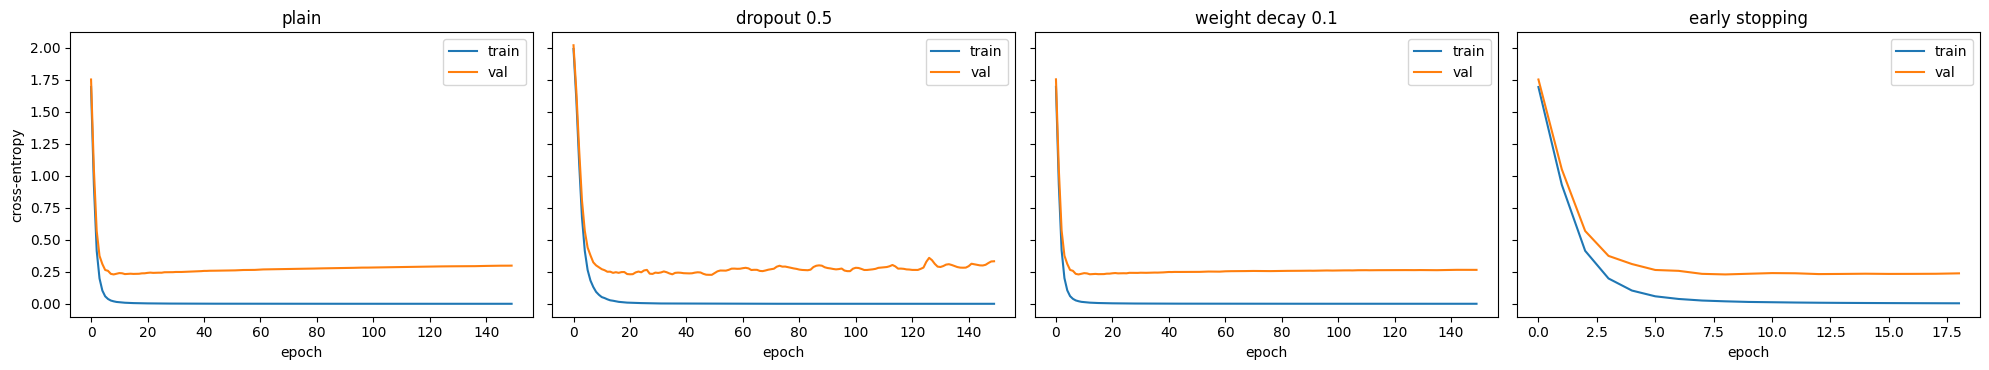

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(20, 3.8), sharey=True)
for ax, (name, h) in zip(axes, hists.items()):
    ax.plot(h["train_loss"], label="train"); ax.plot(h["val_loss"], label="val")
    ax.set_title(name); ax.set_xlabel("epoch"); ax.legend()
axes[0].set_ylabel("cross-entropy"); plt.tight_layout(); plt.show()

**Read the plain curve:** train loss → 0 while validation loss stops falling or turns upward = overfitting.
The model becomes over-confident even when accuracy holds.

**Read the accuracy table honestly:** on this easy dataset, test accuracy barely moves between settings.
What changes is the validation *loss* (confidence) and the cost: early stopping reaches the same accuracy in a
fraction of the epochs. On harder or smaller datasets, the accuracy gap from regularisation is much larger;
try `train_size=100` in section 2 and compare.

## Debugging checklist when a network won't train (from Karpathy's "Recipe")
1. Overfit **one batch** first: loss should go near 0. If not, there is a bug.
2. Check input scaling and label alignment; print a few samples.
3. Loss is NaN → lower learning rate, check for log(0), check data.
4. Forgot `model.eval()` / `torch.no_grad()` at evaluation → dropout still on, wrong numbers.
5. Forgot `optimizer.zero_grad()` → gradients accumulate.

## ✍️ Your turn
1. Prove item 1: train on a single batch of 32 for 200 steps and print the loss.
2. Replace the MLP with a small CNN (`nn.Conv2d` on 1×8×8 inputs). Does it beat the MLP?
3. Add a learning-rate scheduler (`torch.optim.lr_scheduler.CosineAnnealingLR`).
4. Save and reload the best model with `torch.save(model.state_dict(), ...)`.

## 🎯 Interview check
- Write the 4 lines inside a PyTorch training step from memory.
- What do `model.train()` and `model.eval()` change?
- Dropout vs weight decay vs early stopping: how does each reduce overfitting?
- Why does `CrossEntropyLoss` take logits, not softmax probabilities?

In [7]:
# Your code here